In [7]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit
from sklearn.linear_model import Lasso

# =====================================================================
# 1. C-OPTIMIZED SGLD ENGINE (NUMBA)
# =====================================================================
@njit
def _ula_loop(X, Y, beta, lambda_l1, num_steps, burn_in, eta, smooth_eps):
    """Ultra-fast MCMC loop compiled on the fly by Numba."""
    n, d = X.shape
    theta = np.zeros(d)
    
    n_samples = num_steps - burn_in
    samples = np.empty((n_samples, d))
    
    for t in range(num_steps):
        # Data drift (Likelihood)
        predictions = np.dot(X, theta)
        residuals = predictions - Y
        grad_likelihood = beta * (2.0 / n) * np.dot(X.T, residuals)
        
        # Prior drift (Smoothed L1 to ensure differentiability)
        grad_prior = lambda_l1 * (theta / np.sqrt(theta**2 + smooth_eps**2))
        
        # Total drift and diffusion
        drift = - (grad_likelihood + grad_prior)
        noise = np.sqrt(2.0 * eta) * np.random.randn(d)
        
        # Update step
        theta = theta + eta * drift + noise
        
        if t >= burn_in:
            samples[t - burn_in] = theta
            
    return samples

class LangevinAggregator:
    """Aggregation Estimator based on ULA."""
    def __init__(self, num_steps=50000, burn_in=25000, eta=0.001, lambda_l1=0.1, smooth_eps=1e-5):
        self.num_steps = num_steps
        self.burn_in = burn_in
        self.eta = eta
        self.lambda_l1 = lambda_l1
        self.smooth_eps = smooth_eps
        self.posterior_samples_ = None
        self.theta_ew_ = None

    def fit_sample(self, X, Y, beta):
        self.posterior_samples_ = _ula_loop(
            X, Y, float(beta), float(self.lambda_l1), 
            int(self.num_steps), int(self.burn_in), 
            float(self.eta), float(self.smooth_eps)
        )
        self.theta_ew_ = np.mean(self.posterior_samples_, axis=0)
        return self.posterior_samples_

# =====================================================================
# 2. UTILITY FUNCTIONS (Risks and Gelman-Rubin)
# =====================================================================
def true_excess_risk_n(theta, X, F_star):
    """Computes the excess risk ||f_theta - f*||_n^2."""
    predictions = X @ theta
    residuals = predictions - F_star
    return np.mean(residuals**2)

def calculate_r_hat(all_samples_matrix):
    """Computes the Gelman-Rubin index (R_hat) across multiple chains."""
    M = all_samples_matrix.shape[0] # Number of chains
    N = all_samples_matrix.shape[1] # Number of samples per chain
    
    means_per_chain = np.mean(all_samples_matrix, axis=1)
    W = np.mean(np.var(all_samples_matrix, axis=1, ddof=1), axis=0)
    B = N * np.var(means_per_chain, axis=0, ddof=1)
    
    V_hat = (N - 1) / N * W + B / N
    r_hat = np.sqrt(V_hat / W)
    return r_hat

In [3]:
# =====================================================================
# 3. PARAMETERS AND DATA GENERATION
# =====================================================================
D = 10              
N_SAMPLES = 50      
SIGMA_NOISE = 1.0   
LAMBDA_L1 = 0.1     

# Theorem 1 Constants
BETA = N_SAMPLES / (8 * SIGMA_NOISE**2) 
GAMMA = N_SAMPLES / (16 * SIGMA_NOISE**2) 

np.random.seed(42)

# Fixed design X and true theta (sparse)
X = np.random.randn(N_SAMPLES, D)
TRUE_THETA = np.zeros(D)
TRUE_THETA[:3] = [1.5, -1.0, 0.5] 

# Pure signal f*(x) and observations Y
F_STAR = X @ TRUE_THETA
Y = F_STAR + np.random.normal(0, SIGMA_NOISE, N_SAMPLES)

--- Step A: Sampling from the Theoretical Localized Prior (RHS) ---
Theoretical Local Bound Value: 1.5411

--- Step B: Computing Expected Risk of EW Estimator (LHS) ---
Running 100 experiments (generating new noise each time)...
  Experiment 10/100: Risk = 0.1320
  Experiment 20/100: Risk = 0.3295
  Experiment 30/100: Risk = 0.3316
  Experiment 40/100: Risk = 0.3057
  Experiment 50/100: Risk = 0.3482
  Experiment 60/100: Risk = 0.0998
  Experiment 70/100: Risk = 0.0872
  Experiment 80/100: Risk = 0.0657
  Experiment 90/100: Risk = 0.1092
  Experiment 100/100: Risk = 0.2620

FINAL VERIFICATION OF THEOREM 1
Condition to verify: E[ Risk(f_EW) ] <= Bound
Result:              0.1951          <= 1.5411
THEOREM VERIFIED: Empirical expectation respects the bound.


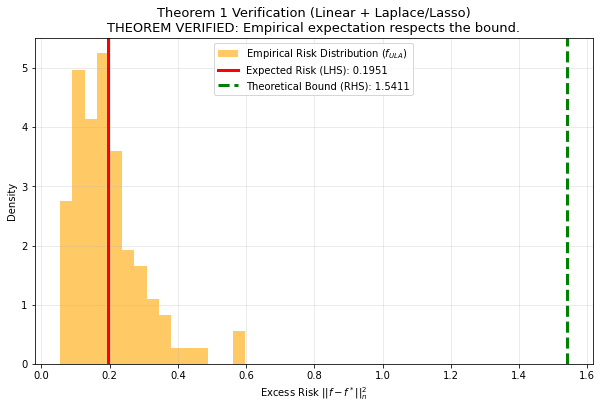

In [8]:
# =====================================================================
# 4. THEOREM 1 VERIFICATION
# =====================================================================
print("--- Step A: Sampling from the Theoretical Localized Prior (RHS) ---")
# The localized prior replaces Beta with Gamma and Y with F_STAR
agg_rhs = LangevinAggregator(num_steps=100000, burn_in=50000, eta=0.001, lambda_l1=LAMBDA_L1)
rhs_samples = agg_rhs.fit_sample(X, F_STAR, GAMMA)

# Risk integral under this prior
rhs_risks = [true_excess_risk_n(th, X, F_STAR) for th in rhs_samples]
theoretical_bound_value = np.mean(rhs_risks)
print(f"Theoretical Local Bound Value: {theoretical_bound_value:.4f}\n")

print("--- Step B: Computing Expected Risk of EW Estimator (LHS) ---")
N_EXPERIMENTS = 100
print(f"Running {N_EXPERIMENTS} experiments (generating new noise each time)...")

excess_risks_list = []
# Model used for the 100 experiments
agg_lhs = LangevinAggregator(num_steps=50000, burn_in=25000, eta=0.001, lambda_l1=LAMBDA_L1)

for i in range(N_EXPERIMENTS):
    # New noise = new dataset
    Y_sim = F_STAR + np.random.normal(0, SIGMA_NOISE, N_SAMPLES)
    
    # Run ULA
    agg_lhs.fit_sample(X, Y_sim, BETA)
    theta_ew_hat = agg_lhs.theta_ew_
    
    # Risk computation
    current_risk = true_excess_risk_n(theta_ew_hat, X, F_STAR)
    excess_risks_list.append(current_risk)
    
    if (i+1) % 10 == 0:
        print(f"  Experiment {i+1}/{N_EXPERIMENTS}: Risk = {current_risk:.4f}")

expected_excess_risk_lhs = np.mean(excess_risks_list)

print("\n===================================================")
print("FINAL VERIFICATION OF THEOREM 1")
print("===================================================")
print("Condition to verify: E[ Risk(f_EW) ] <= Bound")
print(f"Result:              {expected_excess_risk_lhs:.4f}          <= {theoretical_bound_value:.4f}")

if expected_excess_risk_lhs <= theoretical_bound_value:
    result_msg = "THEOREM VERIFIED: Empirical expectation respects the bound."
else:
    result_msg = "THEOREM VIOLATED: Check convergence or parameters."
print(result_msg)

# Plot
plt.figure(figsize=(10, 6))
plt.hist(excess_risks_list, bins=15, alpha=0.6, color='orange', density=True, label="Empirical Risk Distribution ($f_{ULA}$)")
plt.axvline(expected_excess_risk_lhs, color='red', linewidth=3, linestyle='-', label=f"Expected Risk (LHS): {expected_excess_risk_lhs:.4f}")
plt.axvline(theoretical_bound_value, color='green', linewidth=3, linestyle='--', label=f"Theoretical Bound (RHS): {theoretical_bound_value:.4f}")

plt.title(f"Theorem 1 Verification (Linear + Laplace/Lasso)\n{result_msg}", fontsize=13)
plt.xlabel("Excess Risk $||f - f^*||_n^2$")
plt.ylabel("Density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Sampling chain 1...
Sampling chain 2...
Sampling chain 3...


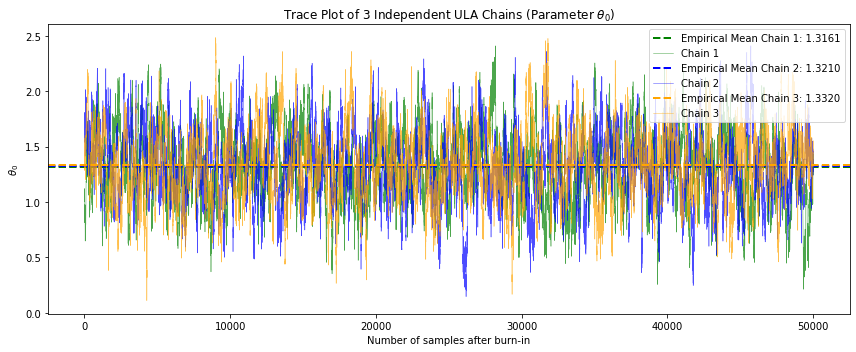


--- Gelman-Rubin Indices per Dimension ---
Parameter theta_0: R_hat = 1.0003 (CONVERGED)
Parameter theta_1: R_hat = 1.0052 (CONVERGED)
Parameter theta_2: R_hat = 1.0026 (CONVERGED)
Parameter theta_3: R_hat = 1.0021 (CONVERGED)
Parameter theta_4: R_hat = 1.0010 (CONVERGED)
Parameter theta_5: R_hat = 1.0118 (CONVERGED)
Parameter theta_6: R_hat = 1.0081 (CONVERGED)
Parameter theta_7: R_hat = 1.0002 (CONVERGED)
Parameter theta_8: R_hat = 1.0009 (CONVERGED)
Parameter theta_9: R_hat = 1.0015 (CONVERGED)
-------------------------------------------------------
Mean of R_hat across all dimensions: 1.0034


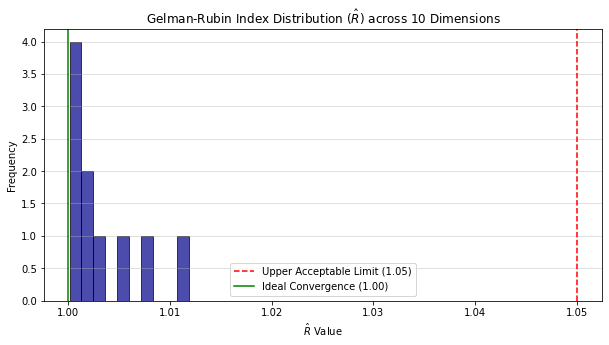

In [9]:
# =====================================================================
# 5. CONVERGENCE DIAGNOSTIC (Gelman-Rubin)
# =====================================================================
n_chains = 3
all_samples = []
colors = ['green', 'blue', 'orange']

plt.figure(figsize=(12, 5))

# Using a longer chain to assess true convergence
agg_check = LangevinAggregator(num_steps=100000, burn_in=50000, eta=0.001, lambda_l1=LAMBDA_L1)

for i in range(n_chains):
    np.random.seed(42 + i) 
    
    print(f"Sampling chain {i+1}...")
    ula_samples = agg_check.fit_sample(X, Y, BETA)
    all_samples.append(ula_samples)
    
    mean_ula_theta0 = np.mean(ula_samples[:, 0])
    plt.axhline(mean_ula_theta0, color=colors[i], linestyle='--', linewidth=2,
            label=f"Empirical Mean Chain {i+1}: {mean_ula_theta0:.4f}")
    
    plt.plot(ula_samples[:, 0], lw=0.5, color=colors[i], alpha=0.7, label=f"Chain {i+1}")

plt.title(f"Trace Plot of {n_chains} Independent ULA Chains (Parameter $\\theta_0$)")
plt.xlabel("Number of samples after burn-in")
plt.ylabel("$\\theta_0$")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

# Final R_hat computation
all_samples_matrix = np.array(all_samples)
r_hat_vector = calculate_r_hat(all_samples_matrix)

print("\n--- Gelman-Rubin Indices per Dimension ---")
for d in range(D):
    r_val = r_hat_vector[d]
    status = "CONVERGED" if r_val < 1.05 else "NOT CONVERGED"
    print(f"Parameter theta_{d}: R_hat = {r_val:.4f} ({status})")

print("-------------------------------------------------------")
print(f"Mean of R_hat across all dimensions: {np.mean(r_hat_vector):.4f}")

# R_hat Histogram
plt.figure(figsize=(10, 5))
plt.hist(r_hat_vector, bins=max(10, D//2), color='darkblue', edgecolor='black', alpha=0.7)
plt.axvline(1.05, color='red', linestyle='--', label="Upper Acceptable Limit (1.05)")
plt.axvline(1.00, color='green', linestyle='-', label="Ideal Convergence (1.00)")
plt.title(f"Gelman-Rubin Index Distribution ($\\hat{{R}}$) across {D} Dimensions")
plt.xlabel("$\\hat{R}$ Value")
plt.ylabel("Frequency")
plt.legend()
plt.grid(axis='y', alpha=0.5)
plt.show()

Lasso Hyperparameter (alpha / lambda): 0.1000
EW Estimator Risk (ULA)  : 0.1766
MAP Estimator Risk (Lasso): 0.0622
L2 Distance between theta_EW and theta_MAP: 0.4044

--- Coefficients Comparison ---
theta_0: ULA=1.3320 | MAP=1.2712 | True=1.5000
theta_1: ULA=-1.2668 | MAP=-1.0816 | True=-1.0000
theta_2: ULA=0.6754 | MAP=0.5729 | True=0.5000
theta_3: ULA=0.0922 | MAP=-0.0000 | True=0.0000
theta_4: ULA=0.0944 | MAP=0.0231 | True=0.0000


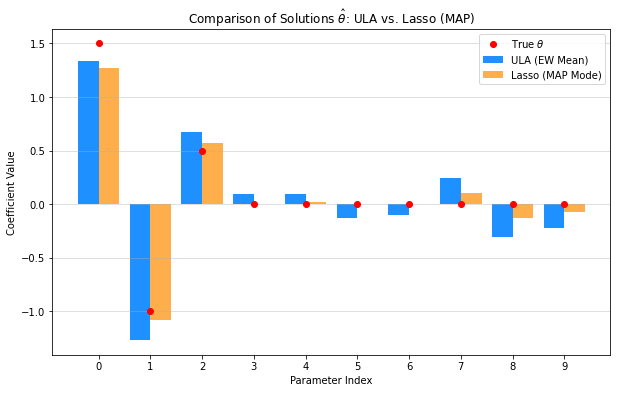

In [10]:
# =====================================================================
# 6. ULA (Mean) vs LASSO (Mode / MAP) COMPARISON
# =====================================================================
# Retrieve the ULA estimator computed in the previous cell
theta_ula_mean = agg_check.theta_ew_

# Compute Lasso (MAP) model
lasso_model = Lasso(alpha=LAMBDA_L1, fit_intercept=False, max_iter=5000) 
lasso_model.fit(X, Y) 
theta_map = lasso_model.coef_

# Compute distances and risks
risk_ula_ew = true_excess_risk_n(theta_ula_mean, X, F_STAR)
risk_map_lasso = true_excess_risk_n(theta_map, X, F_STAR)
dist_ula_map = np.linalg.norm(theta_ula_mean - theta_map)

print(f"Lasso Hyperparameter (alpha / lambda): {LAMBDA_L1:.4f}")
print("===================================================")
print(f"EW Estimator Risk (ULA)  : {risk_ula_ew:.4f}")
print(f"MAP Estimator Risk (Lasso): {risk_map_lasso:.4f}")
print(f"L2 Distance between theta_EW and theta_MAP: {dist_ula_map:.4f}")

print("\n--- Coefficients Comparison ---")
for d in range(min(D, 5)):
    print(f"theta_{d}: ULA={theta_ula_mean[d]:.4f} | MAP={theta_map[d]:.4f} | True={TRUE_THETA[d]:.4f}")

# Parameters visualization
plt.figure(figsize=(10, 6))
d_indices = np.arange(D)

plt.bar(d_indices - 0.2, theta_ula_mean, 0.4, label='ULA (EW Mean)', color='dodgerblue')
plt.bar(d_indices + 0.2, theta_map, 0.4, label='Lasso (MAP Mode)', color='darkorange', alpha=0.7)
plt.plot(d_indices, TRUE_THETA, 'ro', label='True $\\theta$', markersize=6)

plt.title("Comparison of Solutions $\\hat{\\theta}$: ULA vs. Lasso (MAP)")
plt.xlabel("Parameter Index")
plt.ylabel("Coefficient Value")
plt.xticks(d_indices)
plt.legend()
plt.grid(axis='y', alpha=0.5)
plt.show()

**Discussion on Theorem 1 Verification & Lack of Closed Form:**

The empirical verification of Theorem 1 highlights a major numerical challenge when working with a Laplace prior ($L_1$ penalty) instead of a Gaussian prior ($L_2$ penalty).While the left-hand side (LHS) of the theorem — the expected excess risk of our EW estimator — is naturally evaluated through Monte Carlo simulations over multiple datasets, the right-hand side (RHS) presents a theoretical hurdle. For a Gaussian prior, the localized prior bound can be computed exactly via a closed-form analytical solution. However, due to the $L_1$ geometry of the Laplace prior, the integral defining the theoretical bound has no closed form.As a result, we must leverage the Unadjusted Langevin Algorithm (ULA) not only to train our estimator, but also to numerically simulate the localized prior and approximate the theoretical bound itself. The fact that our LHS empirical risk consistently respects this numerically approximated RHS bound (as shown in the distribution plot) empirically validates the theoretical framework, even in the absence of closed-form guarantees.